In [1]:
#Avani Gohil 
#USC ID: 8561210879

In [2]:
#Imports
import pandas as pd
import xgboost as xgb
import re
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, hamming_loss
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

#Regression imports
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import KFold, GridSearchCV, StratifiedKFold
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline

In [3]:
#1s.) Decision Tree Data Loading

#Reading Names File
#with open("Data/diagnosis.names") as f:
    #(f.read())

#Downloading / Storing Data File

#Defining col names
cols = ["temperature", "nausea", "lumbar_pain", "urine_pushing",
        "micturition_pains", "urethra_burning",
        "bladder_inflammation", "nephritis"]

df_data = pd.read_csv(
    "Data/diagnosis.data", 
    header=None, 
    names = cols, 
    sep = "\t",
    decimal = ",",
    encoding="utf-16"
)

#Converting binary data
binary_cols = ["nausea", "lumbar_pain", "urine_pushing", "micturition_pains", 
               "urethra_burning", "bladder_inflammation", "nephritis"]

# Add binary values
df_data[binary_cols] = df_data[binary_cols].replace({"yes": 1, "no": 0}).astype(int)

# Show the first 10 rows
df_data.head(10)

C:\Users\agohi\AppData\Local\Temp\ipykernel_23280\4019064186.py:28: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_data[binary_cols] = df_data[binary_cols].replace({"yes": 1, "no": 0}).astype(int)


,temperature,nausea,lumbar_pain,urine_pushing,micturition_pains,urethra_burning,bladder_inflammation,nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0
5,36.0,0,1,0,0,0,0,0
6,36.2,0,0,1,1,1,1,0
7,36.2,0,1,0,0,0,0,0
8,36.3,0,0,1,1,1,1,0
9,36.6,0,0,1,1,1,1,0


0    30
1    31
2    40
3    19
Name: count, dtype: int64
Depth: 4
Leaves: 6


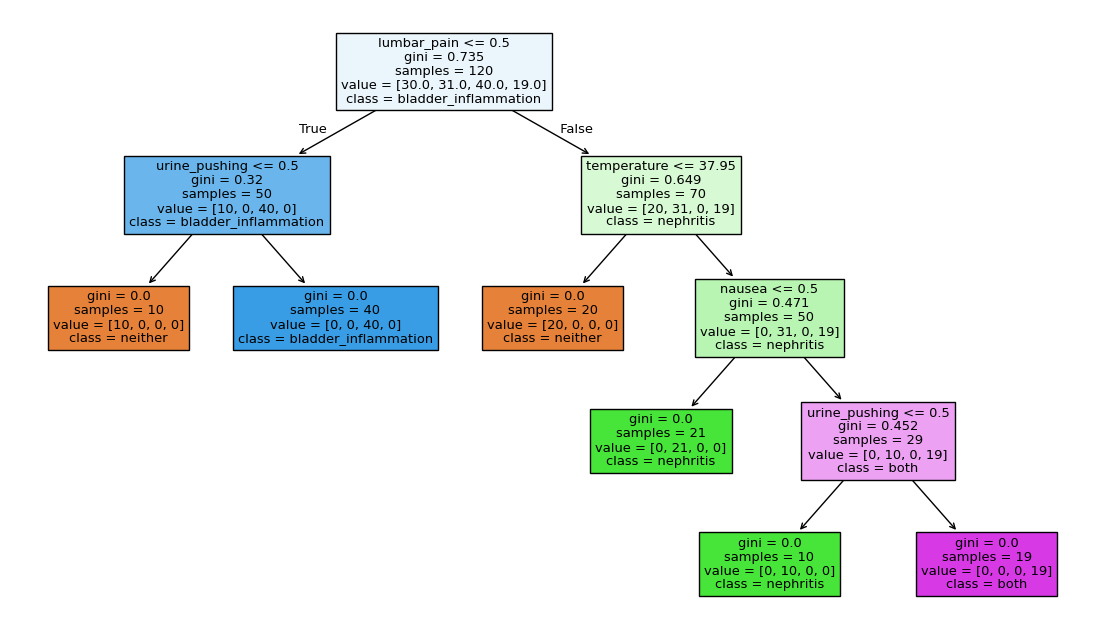

In [4]:
#1b.) Decision Tree and Plotting

#Use Multiclass, Powerset Method to create 4 new classes that are combos of 2 outcome variables (bladder inflam. and nephritis)

# Label powerset to create 4 classes - outcomes
labels = ["bladder_inflammation", "nephritis"]

# Predictors
X = df_data.drop(columns=labels)

# 0 = neither, 1 = nephritis only, 2 = bladder inflammation only, 3 = both
y_powerset = df_data["bladder_inflammation"] * 2 + df_data["nephritis"]
print(y_powerset.value_counts().sort_index())

# Decision Tree Model
dt_clfr = DecisionTreeClassifier(random_state=42)
dt_clfr.fit(X, y_powerset)

print("Depth:", dt_clfr.get_depth())
print("Leaves:", dt_clfr.get_n_leaves())

# Plotting
class_names = ["neither", "nephritis", "bladder_inflammation", "both"]
plt.figure(figsize=(14, 8))
plot_tree(dt_clfr, feature_names=list(X.columns),
          class_names=class_names, filled=True)
plt.show()

In [5]:
#1c - IF-THEN Rules

#Defining function from kdnuggests source code
def tree_to_rules(dt_clfr, feature_names, class_names):
    """Print every root-to-leaf path of a fitted DecisionTreeClassifier as an IF-THEN rule.

    class_names: dict mapping class value -> readable label
    """
    t = dt_clfr.tree_

    def recurse(node, conditions):
        
        if t.children_left[node] == t.children_right[node]:
            predicted = dt_clfr.classes_[np.argmax(t.value[node])]
            n_samples = t.n_node_samples[node]
            cond = " AND ".join(conditions) if conditions else "TRUE"
            print(f"IF {cond}\n   THEN {class_names[predicted]}  ({n_samples} training samples)\n")
            return

        name = feature_names[t.feature[node]]
        thr = t.threshold[node]

        # Left branch: feature <= threshold
        recurse(t.children_left[node], conditions + [f"{name} <= {thr:.2f}"])
        # Right branch: feature > threshold
        recurse(t.children_right[node], conditions + [f"{name} > {thr:.2f}"])

    recurse(0, [])

# Calling the function
class_names = {0: "neither", 1: "nephritis only", 2: "bladder inflammation only", 3: "both"}
tree_to_rules(dt_clfr, list(X.columns), class_names)


IF lumbar_pain <= 0.50 AND urine_pushing <= 0.50
   THEN neither  (10 training samples)

IF lumbar_pain <= 0.50 AND urine_pushing > 0.50
   THEN bladder inflammation only  (40 training samples)

IF lumbar_pain > 0.50 AND temperature <= 37.95
   THEN neither  (20 training samples)

IF lumbar_pain > 0.50 AND temperature > 37.95 AND nausea <= 0.50
   THEN nephritis only  (21 training samples)

IF lumbar_pain > 0.50 AND temperature > 37.95 AND nausea > 0.50 AND urine_pushing <= 0.50
   THEN nephritis only  (10 training samples)

IF lumbar_pain > 0.50 AND temperature > 37.95 AND nausea > 0.50 AND urine_pushing > 0.50
   THEN both  (19 training samples)



Optimal alpha: 0.0
CV accuracy at optimal alpha: 0.9583333333333334
Leaves (Full Decision Tree): 6
Leaves (Pruned Decision Tree): 6
Depth (Full Decision Tree): 4
Depth (Pruned Decision Tree): 4


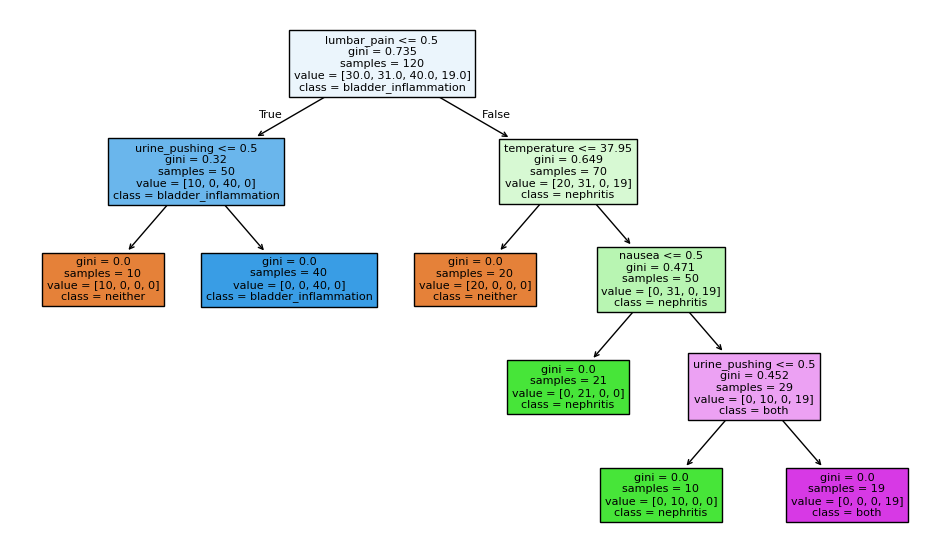

In [6]:
#1d.) Cost-Complexity Pruning to find Minimal Decision Tree

path = dt_clfr.cost_complexity_pruning_path(X, y_powerset)
alphas = path.ccp_alphas[:-1]  #generating the alpha values to test for penalty       

#cross-validating a classifier tree for each alpha value
scores = []
for a in alphas:
    clf_model = DecisionTreeClassifier(random_state=42, ccp_alpha=a)
    scores.append(cross_val_score(clf_model, X, y_powerset, cv=5).mean())

#Choosing the best alpha
best_score = max(scores)
best_alpha = alphas[0]
for a, s in zip(alphas, scores):
    if round(s, 6) == round(best_score, 6) and a > best_alpha:
        best_alpha = a
print("Optimal alpha:", best_alpha)
print("CV accuracy at optimal alpha:", best_score)

#Refitting the pruned tree
pruned = DecisionTreeClassifier(random_state=42, ccp_alpha=best_alpha)
pruned.fit(X, y_powerset)

#Printing output for the pruned tree
print("Leaves (Full Decision Tree):", dt_clfr.get_n_leaves())
print("Leaves (Pruned Decision Tree):", pruned.get_n_leaves())
print("Depth (Full Decision Tree):", dt_clfr.get_depth())
print("Depth (Pruned Decision Tree):", pruned.get_depth())

plt.figure(figsize=(12, 7))
plot_tree(pruned, feature_names=list(X.columns),
          class_names=["neither", "nephritis", "bladder_inflammation", "both"],
          filled=True)
plt.show()

In [7]:
#2 LASSO and Boosting for Regression

#2a.) Downloading data 

#Reading Names File
#with open("Data/communities.names") as f:
    #print(f.read())

#Parsing through names file for adding predictor names to data file
names = []
with open("Data/communities.names") as f:
    for line in f:
        match = re.match(r"^--\s+(\w+):", line.strip())   # "-- name:" with a single-token name
        if match:
            names.append(match.group(1))

# keep only the range of predictors wanted
start = names.index("state")
end = len(names) - 1 - names[::-1].index("ViolentCrimesPerPop") 
names = names[start:end + 1]

print(len(names))

df_comm = pd.read_csv(
    "Data/communities.data", 
    header=None, 
    na_values="?",
)
assert len(names) == df_comm.shape[1], (len(names), df_comm.shape[1])
df_comm.columns = names

128


In [8]:
#Checking the df
print(df_comm.head(10))

   state  county  community        communityname  fold  population  \
0      8     NaN        NaN         Lakewoodcity     1        0.19   
1     53     NaN        NaN          Tukwilacity     1        0.00   
2     24     NaN        NaN         Aberdeentown     1        0.00   
3     34     5.0    81440.0  Willingborotownship     1        0.04   
4     42    95.0     6096.0    Bethlehemtownship     1        0.01   
5      6     NaN        NaN    SouthPasadenacity     1        0.02   
6     44     7.0    41500.0          Lincolntown     1        0.01   
7      6     NaN        NaN            Selmacity     1        0.01   
8     21     NaN        NaN        Hendersoncity     1        0.03   
9     29     NaN        NaN          Claytoncity     1        0.01   

   householdsize  racepctblack  racePctWhite  racePctAsian  ...  LandArea  \
0           0.33          0.02          0.90          0.12  ...      0.12   
1           0.16          0.12          0.74          0.45  ...      0.02  

In [9]:
#2a Splitting data into training and testing set

#Redefining Variables
dropped_preds = ["state", "county", "community", "communityname", "fold"]

df_comm = df_comm.drop(columns=dropped_preds)  #taking out the non-predictive columns

target = "ViolentCrimesPerPop"

X = df_comm.drop(columns=target)
y = df_comm[target]

X_train, y_train = X.iloc[:1495], y.iloc[:1495]
X_test, y_test = X.iloc[1495:], y.iloc[1495:]

In [10]:
#2b - Data Imputation for Missing Values

#Checking data type for missing values
df_comm.dtypes
df_comm.dtypes.value_counts()

impute = SimpleImputer(strategy = "mean", keep_empty_features=True)
impute.fit(X_train)

X_train_imputed = impute.transform(X_train)   # put NaN with imputed means
X_test_imputed  = impute.transform(X_test)    # does the same to testing data set

X_train_imputed = pd.DataFrame(X_train_imputed, columns=X_train.columns, index=X_train.index)
X_test_imputed  = pd.DataFrame(X_test_imputed,  columns=X_test.columns,  index=X_test.index)

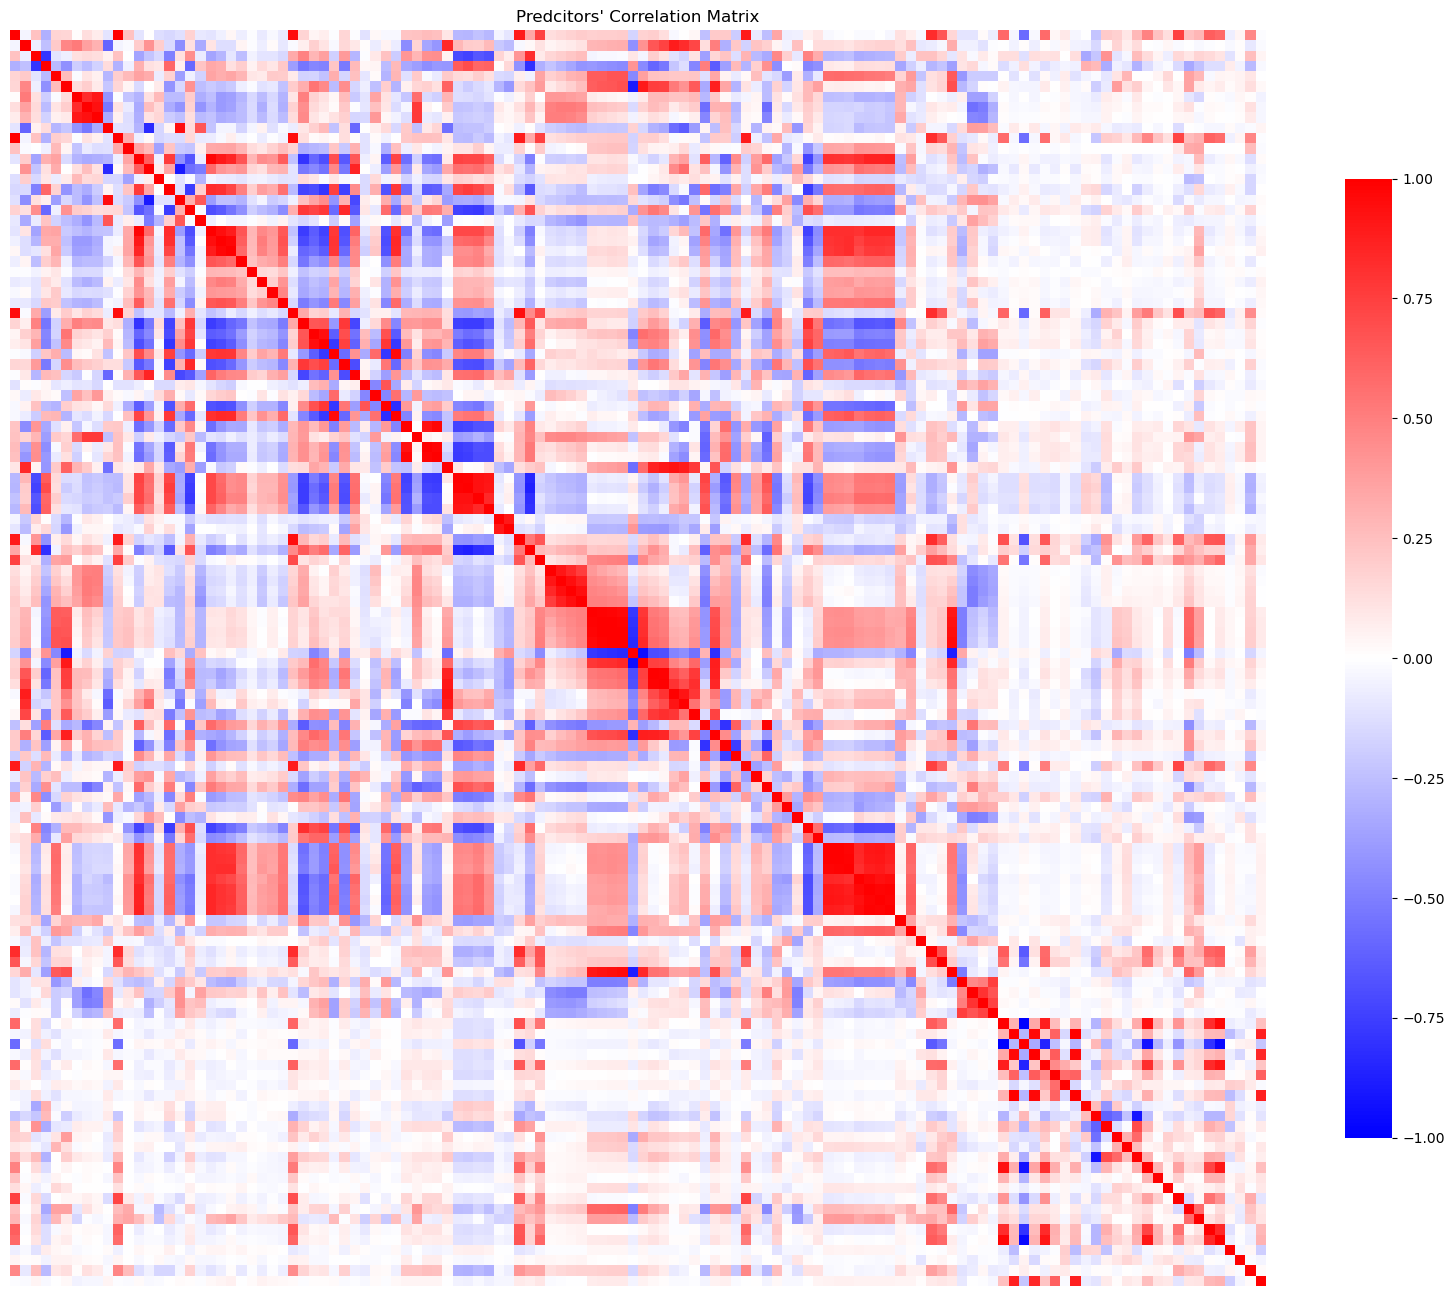

In [11]:
#2c - Correlation Matrix

corr_matrix = X_train_imputed.corr()

plt.figure(figsize=(16, 14))
sns.heatmap(corr_matrix, cmap="bwr", vmin=-1, vmax=1, center=0,
            xticklabels=False, yticklabels=False, 
            square=True, cbar_kws={"shrink": 0.7})

plt.title("Predcitors' Correlation Matrix")
plt.tight_layout()
plt.show()

In [12]:
#2d - Calculating the Coefficient of Variation for each feature

#CV = s / m (s is sample SD and m is sample mean)

cv_results = X_train_imputed.std() / X_train_imputed.mean()

print(cv_results.sort_values(ascending=False))

NumStreet              4.292923
NumInShelters          3.470952
NumIlleg               3.058964
NumImmig               2.926635
LemasPctOfficDrugUn    2.552946
                         ...   
NumKindsDrugsSeiz      0.144382
RacialMatchCommPol     0.134853
PctPolicWhite          0.122813
LemasPctPolicOnPatr    0.115739
LemasSwFTFieldOps      0.064288
Length: 122, dtype: float64


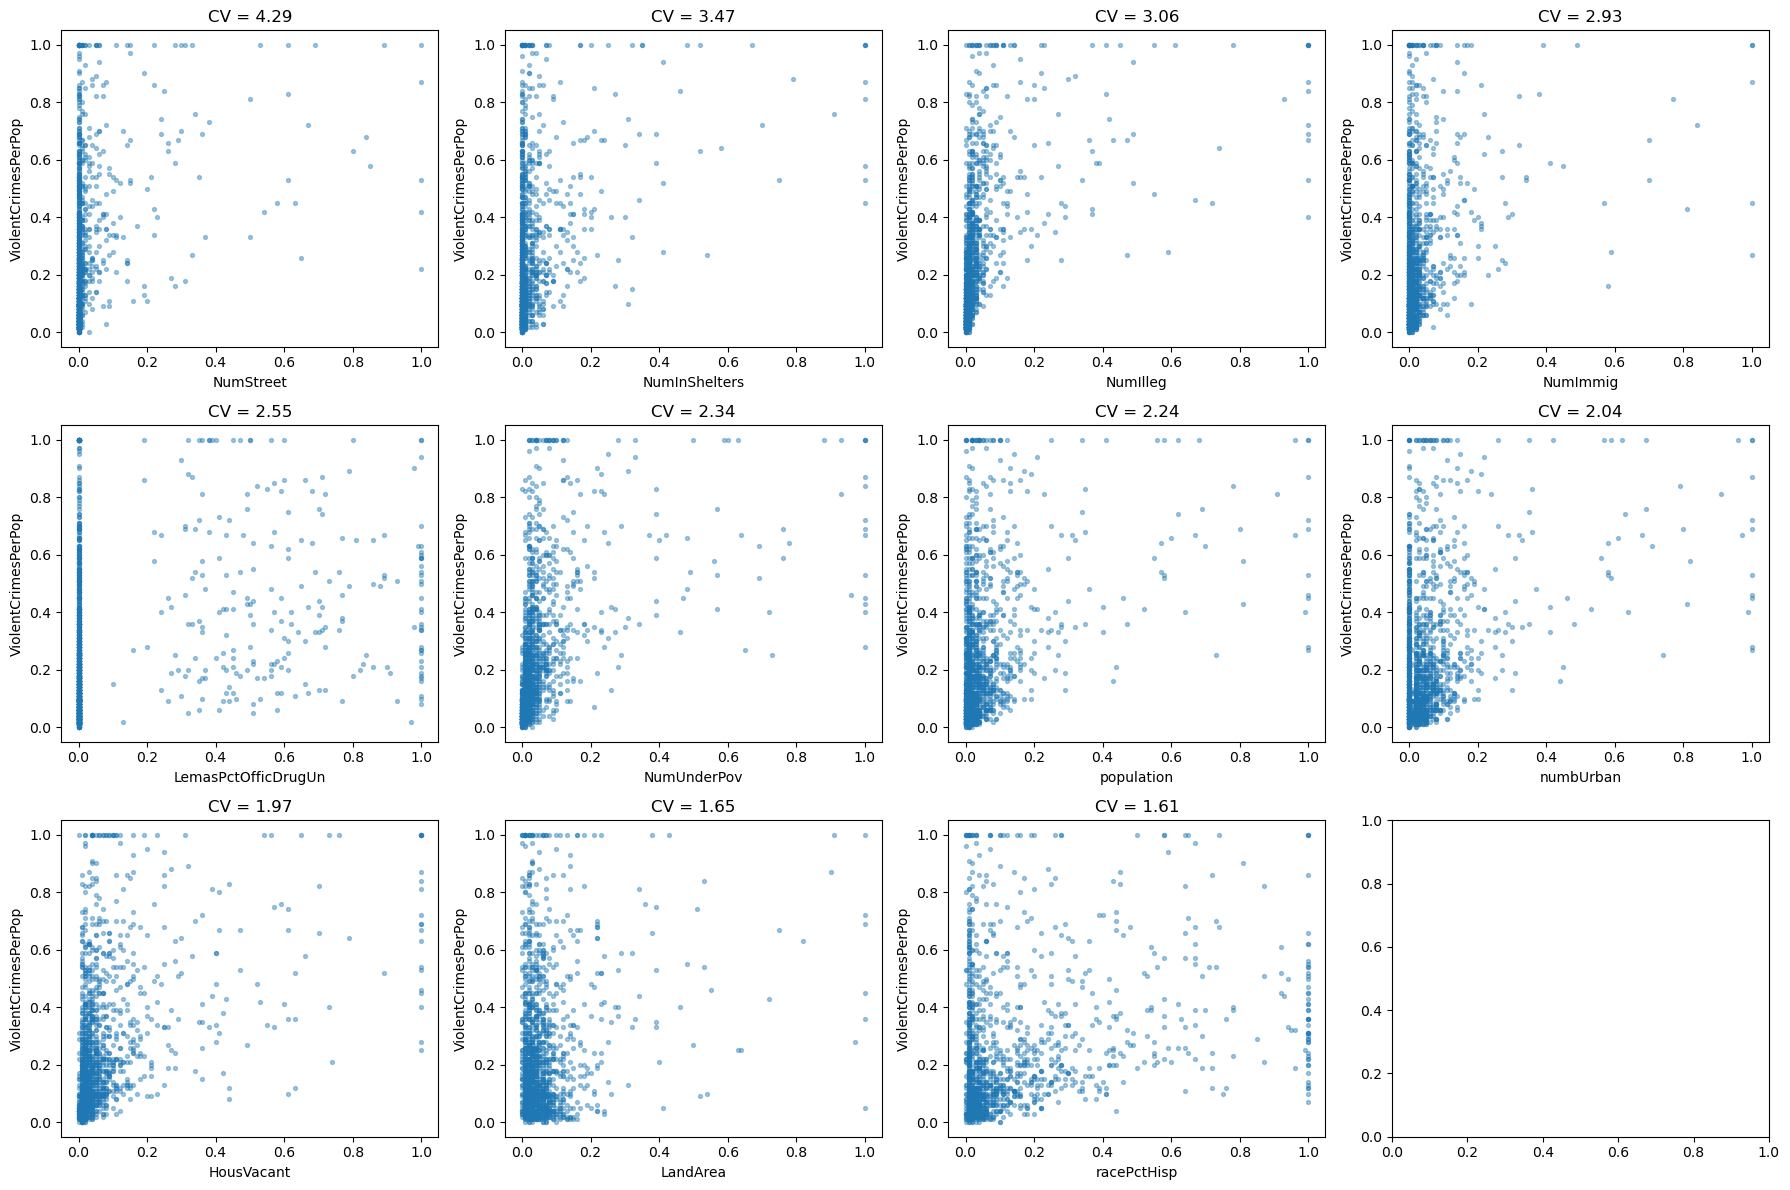

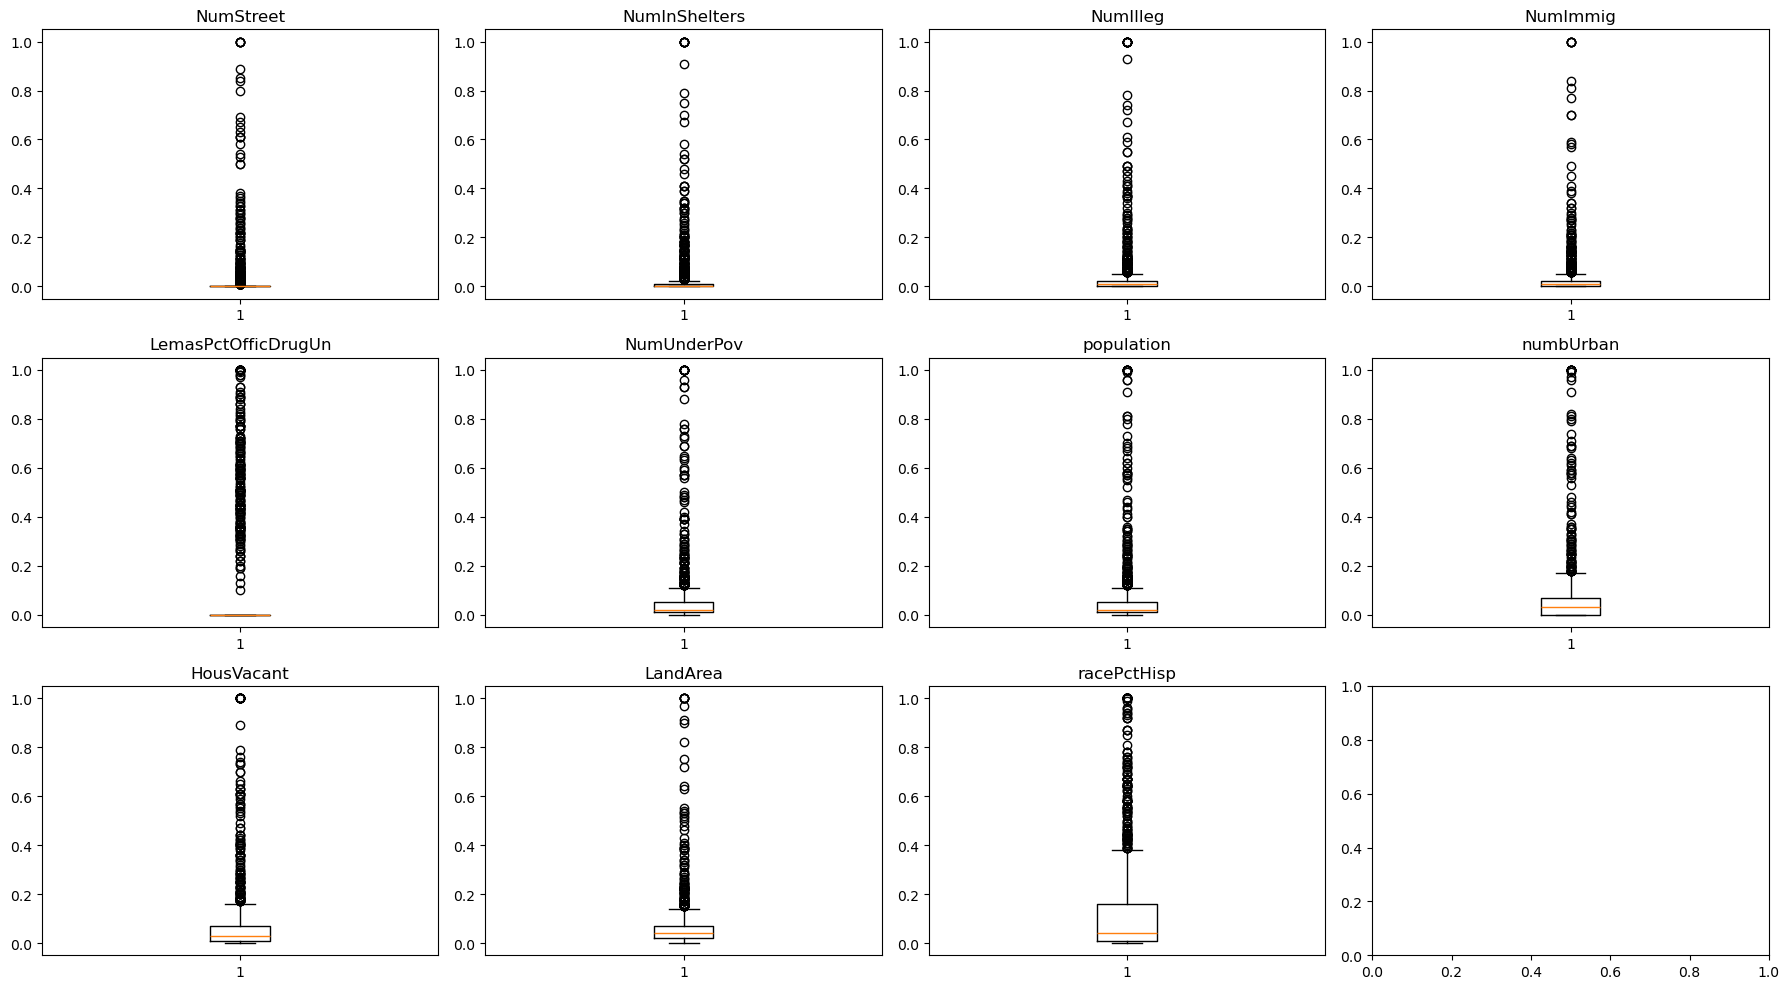

In [13]:
#2e Scatter Plots and Box Plots for Predictors with Highest CV

#the sqrt of 128 is approx 11 predictors, so plotting for them

top_features = cv_results.sort_values(ascending=False).head(11).index

#Scatter Plots
fig, axes = plt.subplots(3, 4, figsize=(18, 12))
axes = axes.ravel()

for ax, feat in zip(axes, top_features):
    ax.scatter(X_train_imputed[feat], y_train, s=8, alpha=0.4)
    ax.set_xlabel(feat)
    ax.set_ylabel("ViolentCrimesPerPop")
    ax.set_title(f"CV = {cv_results[feat]:.2f}")

plt.tight_layout()
plt.show()

#Box Plots
fig, axes = plt.subplots(3, 4, figsize=(18, 10))
axes = axes.ravel()

for ax, feat in zip(axes, top_features):
    ax.boxplot(X_train_imputed[feat].dropna(), vert=True)
    ax.set_title(feat)

plt.tight_layout()
plt.show()

2e.)

From the scatter plots, the High CV indicates that the feature spreads out significantly relative to its average size. The highest-CV features are normalized variables with right-skew, with most communities near zero and a few large cities near one. The scatter plots have many overlapping points and extreme values, so we cannot conclude significance from them alone. Formal measures (correlations, regression coefficients, and LASSO selection) are needed.

In [14]:
#2f.) Linear Model using Least Squares

ols_model = LinearRegression()
ols_model.fit(X_train_imputed, y_train)

y_pred = ols_model.predict(X_test_imputed) #testing 

#Test Error
test_mse = mean_squared_error(y_test, y_pred)
print("Test MSE: ", test_mse)
print("Test RMSE:", test_mse ** 0.5)

Test MSE:  0.018141971135530104
Test RMSE: 0.1346921346461259


In [15]:
#2g.) Ridge Regression Model

kf = KFold(n_splits=5, shuffle=True, random_state=0)  #k-fold cross validation

ridge = RidgeCV(alphas=np.logspace(-3, 3, 50), cv=kf)  #selecting candidate lambdas
ridge.fit(X_train_imputed, y_train)
print("Chosen lambda:", ridge.alpha_)

y_pred_ridge = ridge.predict(X_test_imputed) #testing

test_mse_ridge = mean_squared_error(y_test, y_pred_ridge)
print("Test MSE: ", test_mse_ridge)
print("Test RMSE:", test_mse_ridge ** 0.5)

Chosen lambda: 2.023589647725158
Test MSE:  0.01761965343155778
Test RMSE: 0.1327390426044944


In [16]:
#2h.) Lasso Regression Model (nonstandardized)

lasso = LassoCV(alphas=np.logspace(-3, 3, 50), cv=kf)  #selecting lambdas that are 
lasso.fit(X_train_imputed, y_train)
print("Chosen lambda:", lasso.alpha_)

y_pred_lasso = lasso.predict(X_test_imputed) #testing

test_mse_lasso = mean_squared_error(y_test, y_pred_lasso)
print("Test MSE: ", test_mse_lasso)
print("Test RMSE:", test_mse_lasso ** 0.5)

#Selected Features
bool_mask = lasso.coef_ != 0
selected_feats = X_train.columns[bool_mask]

print("Selected features:", list(selected_feats))

Chosen lambda: 0.001
Test MSE:  0.017545275227528963
Test RMSE: 0.13245857929001414
Selected features: ['racepctblack', 'racePctWhite', 'agePct12t29', 'pctUrban', 'pctWPubAsst', 'AsianPerCap', 'MalePctDivorce', 'PctKids2Par', 'PctYoungKids2Par', 'PctWorkMom', 'PctIlleg', 'PctRecImmig10', 'PctPersDenseHous', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'MedRentPctHousInc', 'MedOwnCostPctIncNoMtg', 'NumStreet', 'PctForeignBorn', 'PctSameCity85', 'LemasGangUnitDeploy', 'LemasPctOfficDrugUn']


In [17]:
#2h Lasso Regression Model (standardized)

scaler = StandardScaler()

X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train_imputed),
                              columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test_imputed),
                             columns=X_test.columns, index=X_test.index)

lasso_std = LassoCV(alphas=np.logspace(-3, 3, 50), cv=kf)
lasso_std.fit(X_train_scaled, y_train)

y_pred_lasso_std = lasso_std.predict(X_test_scaled)

bool_mask = lasso.coef_ != 0
selected_feats = X_train_scaled.columns[bool_mask]
print("Selected features (standardized):", list(selected_feats))

test_mse_lasso_stdrd = mean_squared_error(y_test, y_pred_lasso_std)
print("Test MSE: ", test_mse_lasso_stdrd)
print("Test RMSE:", test_mse_lasso_stdrd ** 0.5)
print()
print(f"The MSE for Lasso with unstandardized data is {test_mse_lasso:.4f} and for standardized model {test_mse_lasso_stdrd:.4f}.")

Selected features (standardized): ['racepctblack', 'racePctWhite', 'agePct12t29', 'pctUrban', 'pctWPubAsst', 'AsianPerCap', 'MalePctDivorce', 'PctKids2Par', 'PctYoungKids2Par', 'PctWorkMom', 'PctIlleg', 'PctRecImmig10', 'PctPersDenseHous', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'MedRentPctHousInc', 'MedOwnCostPctIncNoMtg', 'NumStreet', 'PctForeignBorn', 'PctSameCity85', 'LemasGangUnitDeploy', 'LemasPctOfficDrugUn']
Test MSE:  0.01775814926021371
Test RMSE: 0.13325970606381252

The MSE for Lasso with unstandardized data is 0.0175 and for standardized model 0.0178.


In [18]:
len(df_comm.columns)

123

In [19]:
#2i PCR Model with PCA chosen via cross validation

max_k = X_train_scaled.shape[1]
k_cv_mses = {}

for k in range(1, max_k + 1):
    pcr_model = make_pipeline(PCA(n_components=k), LinearRegression())
    scores = cross_val_score(pcr_model, X_train_scaled, y_train,
                             cv=kf, scoring="neg_mean_squared_error")
    k_cv_mses[k] = -scores.mean()

best_k = min(k_cv_mses, key=k_cv_mses.get)
print(f"Selected M = {best_k} with cross-validated MSE = {k_cv_mses[best_k]:.5f}")

# Refit with M on the full training set
pcr_final = make_pipeline(PCA(n_components=best_k), LinearRegression())
pcr_final.fit(X_train_scaled, y_train)
y_pred_pcr = pcr_final.predict(X_test_scaled)

test_mse_pcr = mean_squared_error(y_test, y_pred_pcr)
print("Test MSE: ", test_mse_pcr)
print("Test RMSE:", test_mse_pcr ** 0.5)

Selected M = 97 with cross-validated MSE = 0.01953
Test MSE:  0.01846608542598296
Test RMSE: 0.13588997544330841


In [20]:
#2j L1 Penalized Gradient Boosting Tree

#Calling xgboost method
xgb_model = xgb.XGBRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=4,
    reg_lambda=0.0, 
    eval_metric="rmse",
    random_state=42,
)

# Different alpha values to try for regularization
param_grid = {
    "reg_alpha": [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
}

# 5-fold CV
grid_search = GridSearchCV(
    estimator=xgb_model,
    param_grid=param_grid,
    cv=5, 
    scoring="neg_mean_squared_error",
    verbose=1,
    n_jobs=-1,
    error_score="raise"
)

# 5. Fit the model and find the optimal alpha
grid_search.fit(X_train_imputed, y_train)

# Best alpha value and accuracy
cv_mse = -grid_search.best_score_
print(f"Optimal alpha: {best_alpha}")
print(f"Optimal CV MSE: {cv_mse:.5f} | CV RMSE: {cv_mse ** 0.5:.5f}")

# Final Prediction
chosen_model = grid_search.best_estimator_
predictions = chosen_model.predict(X_test_imputed)

#Test error for XGB model
test_mse_xgb = mean_squared_error(y_test, predictions)
print("Test MSE: ", test_mse_xgb)
print("Test RMSE:", test_mse_xgb ** 0.5)

Fitting 5 folds for each of 6 candidates, totalling 30 fits
Optimal alpha: 0.0
Optimal CV MSE: 0.02045 | CV RMSE: 0.14299
Test MSE:  0.016111695446388262
Test RMSE: 0.12693185355295283


In [21]:
print("Missing values in y_train:", y_train.isnull().sum()) 

Missing values in y_train: 0
